In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511067/notebook

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511067/notebook


In [2]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil

KB kanal B   : 1.33
KB kanal G   : 1.83
KB kanal R   : 10.99
KB kanal Gray: 5.26
KB kanal H   : 7.50
KB kanal S   : 0.37
KB kanal V   : 3.65


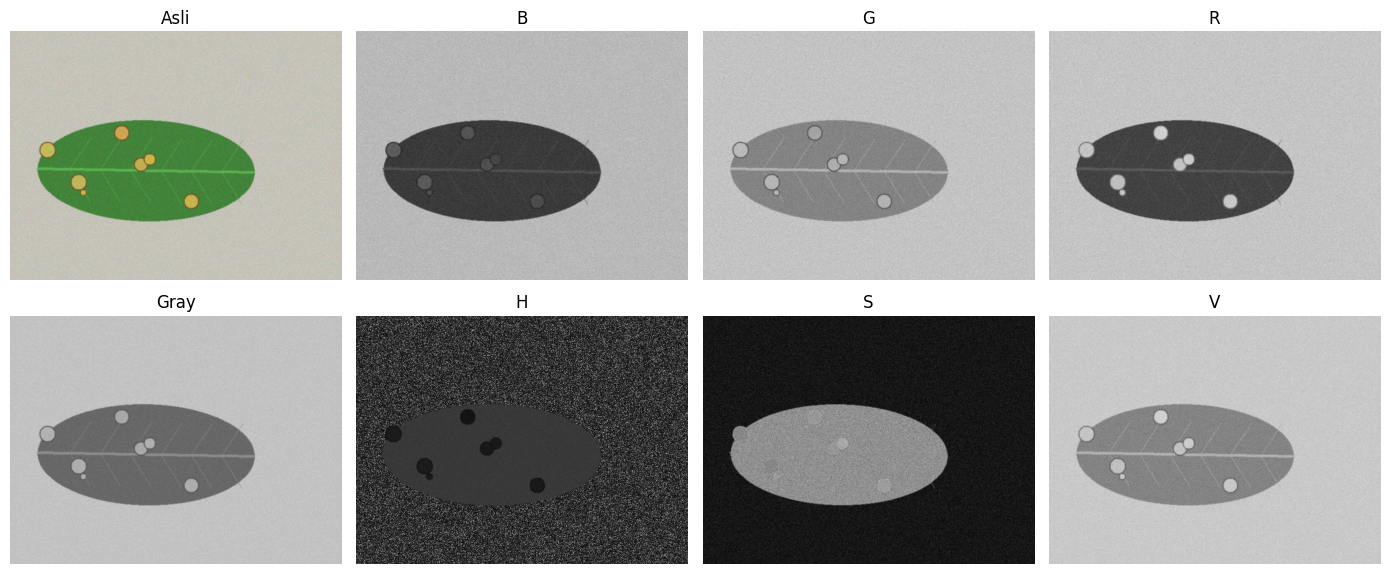

In [3]:
from utils_cv import kontras_bercak
nama = "teh_041.png" # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [4]:
bercak = np.uint8([[[86, 178, 196]]])  # urutan BGR
daun   = np.uint8([[[60, 136, 52]]])
for nm, p in [("bercak", bercak), ("daun", daun)]:
    print(nm, "gray:", cv2.cvtColor(p, cv2.COLOR_BGR2GRAY)[0, 0],
          "| H,S,V:", cv2.cvtColor(p, cv2.COLOR_BGR2HSV)[0, 0])

bercak gray: 173 | H,S,V: [ 25 143 196]
daun gray: 102 | H,S,V: [ 63 158 136]


In [5]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=5.78
fx=0.2: ukuran (96, 128), KB=4.83
fx=0.1: ukuran (48, 64), KB=3.46
fx=0.05: ukuran (24, 32), KB=1.82
k=1: 2 level, KB=3.69
k=2: 3 level, KB=3.69
k=3: 5 level, KB=4.24
k=4: 10 level, KB=5.03
k=8: 144 level, KB=5.26


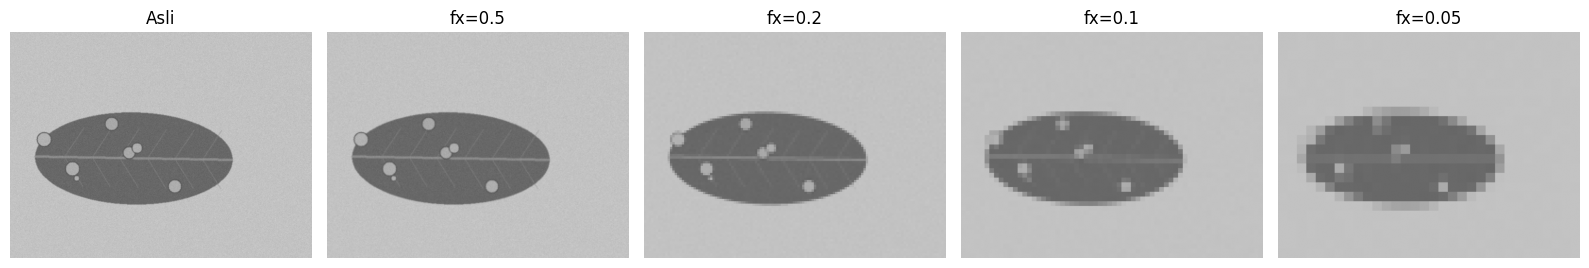

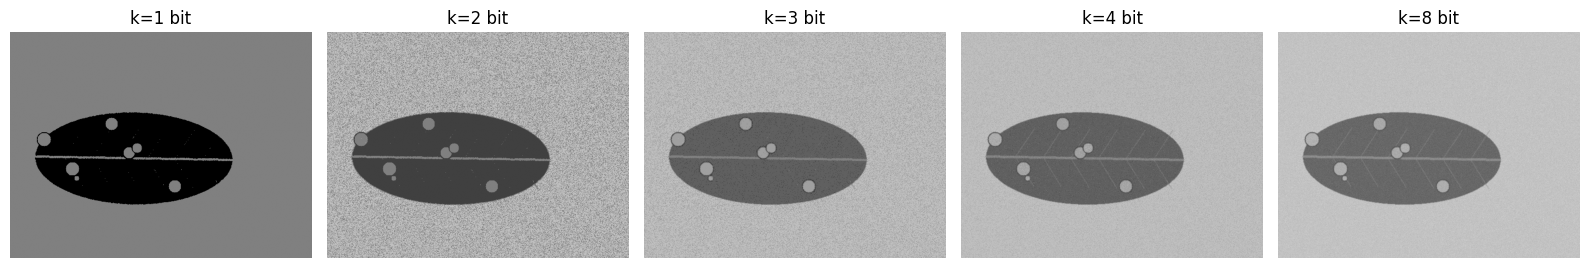

In [6]:
fxs = [0.5, 0.2, 0.1, 0.05]
hasil_samp = []
for fx in fxs:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    hasil_samp.append(cv2.resize(kecil, gray.shape[::-1],
                                 interpolation=cv2.INTER_NEAREST))
tampil([gray] + hasil_samp, ["Asli"] + [f"fx={f}" for f in fxs],
       baris=1, ukuran=(16, 3.5))

ks = [1, 2, 3, 4, 8]
hasil_kuant = [(gray // (256 // 2 ** k)) * (256 // 2 ** k) for k in ks]
tampil(hasil_kuant, [f"k={k} bit" for k in ks], baris=1, ukuran=(16, 3.5))

In [7]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.21  0.45   5.40  1.72  4.88  0.80  1.03
gelap           1.88  1.87  11.26  5.36  6.07  0.92  4.10
kontras_rendah  0.70  0.53   3.92  2.25  2.01  0.26  1.52
normal          2.25  1.44  10.12  5.05  7.26  0.92  3.27
terang          2.52  0.75   6.68  3.69  5.14  1.33  1.88


In [8]:
baris = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb_ringan = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb_ringan)
tabel_kb_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.38  0.51  4.60  1.11  5.47  1.05  0.66
gelap           0.68  1.02  6.49  2.04  4.88  0.74  1.41
kontras_rendah  0.40  0.50  3.91  1.49  3.01  0.45  0.61
normal          1.34  0.86  7.66  2.84  7.15  0.82  1.37
terang          0.93  0.31  5.37  2.22  4.63  0.74  0.77


teh_021.png: KB R=8.07 | KB Gray=2.03
teh_045.png: KB R=6.04 | KB Gray=2.25


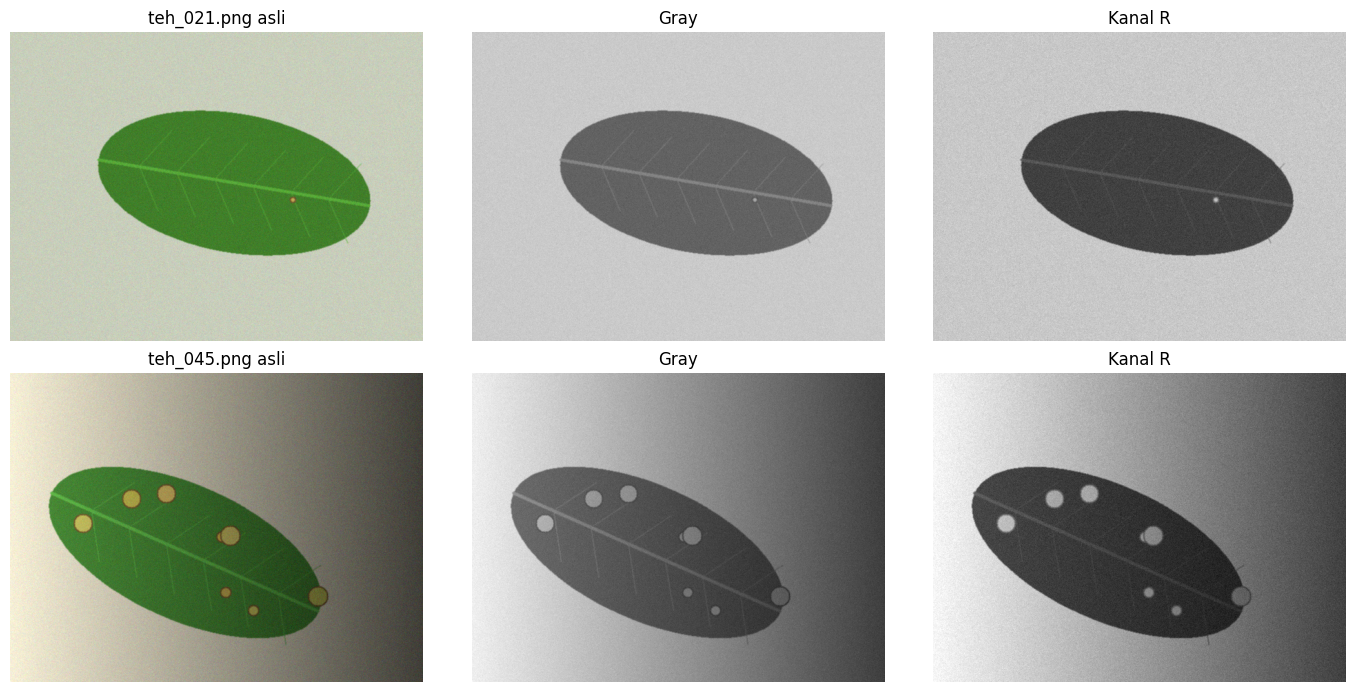

In [9]:
panel, judul = [], []
for nama in ["teh_021.png", "teh_045.png"]:
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    r = img[:, :, 2]  # kanal R (indeks BGR: 2)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    print(f"{nama}: KB R={kontras_bercak(r, md, mb):.2f} | "
          f"KB Gray={kontras_bercak(gray, md, mb):.2f}")
    panel += [img, gray, r]
    judul += [f"{nama} asli", "Gray", "Kanal R"]
tampil(panel, judul, baris=2, ukuran=(14, 7))
plt.savefig("../hasil/b2_kanal_terbaik.png")

In [10]:
!ls ../hasil

b1_bgr_rgb.png			 b4_grafik_waktu.png
b1_pipeline.png			 b4_psnr_12_normal.csv
b1_tabel_risiko.csv		 b4_tabel_penapis.csv
b2_kanal_terbaik.png		 b5_crop_bercak.png
b2_kb_kanal.csv			 b5_panel_sehat_final.png
b2_kb_kanal_ringan.csv		 b5_panel_sehat.png
b3_clahe_V_vs_BGR.png		 b5_pipeline_final.png
b3_histogram_5kondisi.png	 b5_tabel12_final.csv
b3_histogram_ringan.png		 b5_tradeoff_mitigasi.png
b3_perbaikan_bayangan.png	 b5_uji_bercak_palsu.csv
b3_perbaikan_gelap.png		 b5_uji_bercak_palsu_final.csv
b3_perbaikan_kontras_rendah.png  b5_uji_mitigasi_kb.csv
b3_perbaikan_terang.png		 b5_uji_mitigasi_ringkas.csv
b4_crop_bercak.png		 b5_uji_mitigasi_sehat.csv
b4_di_vs_kernel.png		 param_praproses.json
b4_grafik_psnr.png
